In [ ]:
#___Data preprocessing___
# Chargement du dataset
import pandas as pd
import numpy as np

data = pd.read_csv("insurance.csv", sep = ",")
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# Inspection des donnés
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
# Gestion des valeurs manquantes
print("\nMissing values per column:")
print(data.isna().sum())


Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [ ]:
# Gestion des doublons
duplicates = data.duplicated().sum()
print("Number of duplicate rows in the first dataset:", duplicates)

df = data.drop_duplicates(subset=None, keep='first', inplace=False)
duplicates_b = df.duplicated().sum()
print("Number of duplicate rows in the first dataset:", duplicates_b)

Number of duplicate rows in the first dataset: 1
Number of duplicate rows in the first dataset: 0


In [ ]:
# Categorisation des variables et encodage des variables numériques
# Categorisation des variables
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
print("Colonnes numériques :", list(num_cols))
cat_cols = df.select_dtypes(include=['object']).columns
print("Colonnes catégorielles :", list(cat_cols))

Colonnes numériques : ['age', 'bmi', 'children', 'charges']
Colonnes catégorielles : ['sex', 'smoker', 'region']


In [ ]:
# Encodage des variables numériques
df_encoded = pd.get_dummies(df, drop_first=True)

print("✅ Données après encodage :")
print(df_encoded.head())
print("\nNombre de colonnes après transformation :", len(df_encoded.columns))


✅ Données après encodage :
   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400     False        True             False   
1   18  33.770         1   1725.55230      True       False             False   
2   28  33.000         3   4449.46200      True       False             False   
3   33  22.705         0  21984.47061      True       False              True   
4   32  28.880         0   3866.85520      True       False              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  

Nombre de colonnes après transformation : 9


In [ ]:
# Standardisation
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

cols_to_scale = ['age', 'bmi', 'children']
df_encoded[cols_to_scale] = scaler.fit_transform(df_encoded[cols_to_scale])

print("✅ Données après standardisation :")
df_encoded.head()

✅ Données après standardisation :


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,-1.440418,-0.453160,-0.909234,16884.92400,False,True,False,False,True
1,-1.511647,0.509422,-0.079442,1725.55230,True,False,False,True,False
2,-0.799350,0.383155,1.580143,4449.46200,True,False,False,True,False
3,-0.443201,-1.305052,-0.909234,21984.47061,True,False,True,False,False
4,-0.514431,-0.292456,-0.909234,3866.85520,True,False,True,False,False


In [ ]:
# Information sur la base finale
df_encoded.describe()

,age,bmi,children,charges
count,1.337000e+03,1.337000e+03,1.337000e+03,1337.000000
mean,-6.643070e-17,-2.285216e-16,3.852980e-17,13279.121487
std,1.000374e+00,1.000374e+00,1.000374e+00,12110.359656
min,-1.511647e+00,-2.411119e+00,-9.092342e-01,1121.873900
25%,-8.705798e-01,-7.171725e-01,-9.092342e-01,4746.344000
50%,-1.582291e-02,-4.320166e-02,-7.944162e-02,9386.161300
75%,8.389340e-01,6.619260e-01,7.503509e-01,16657.717450
max,1.764921e+00,3.684136e+00,3.239729e+00,63770.428010


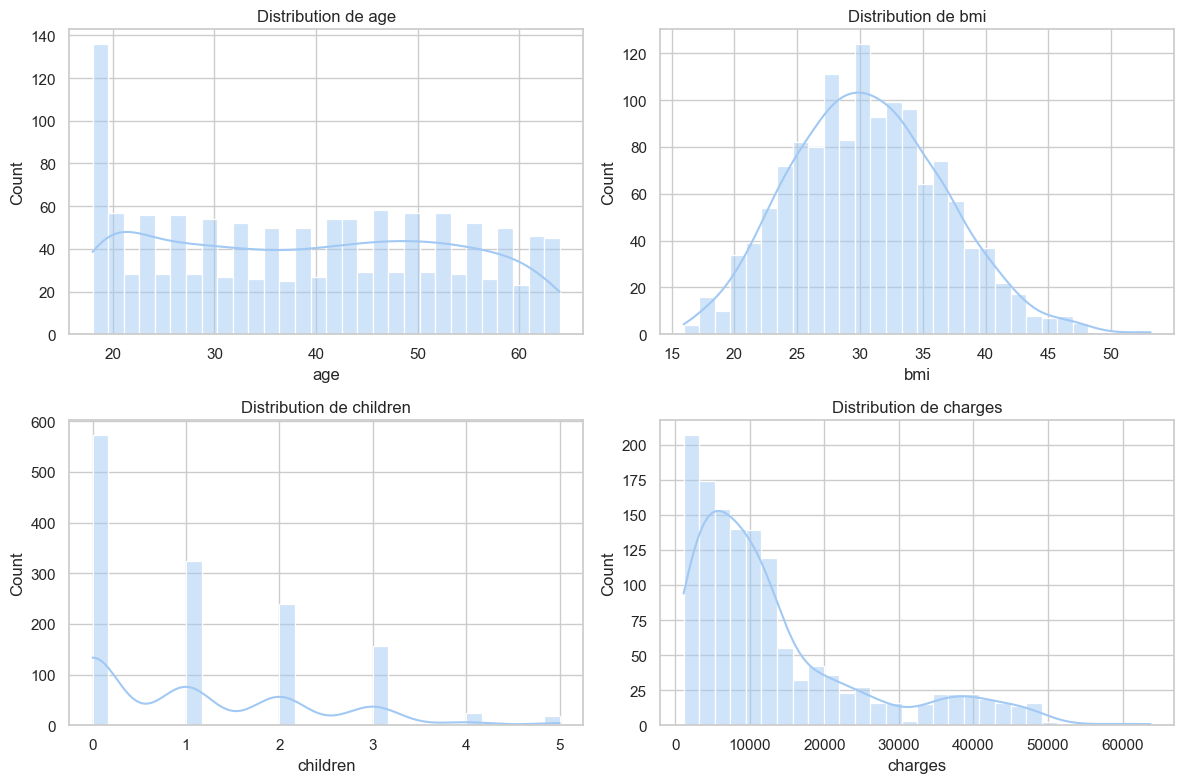

In [ ]:
#___Comprendre la base___
# Histogramme illustrant la distribution des variables numériques
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", palette="pastel")
num_cols = ['age', 'bmi', 'children', 'charges']

plt.figure(figsize=(12, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"Distribution de {col}")
plt.tight_layout()
plt.show()

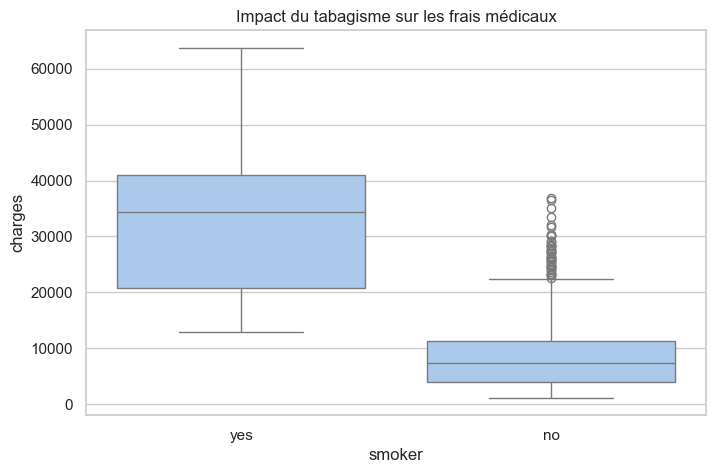

In [ ]:
# Analyse de l'impact du tabagisme
plt.figure(figsize=(8, 5))
sns.boxplot(x='smoker', y='charges', data=df)
plt.title("Impact du tabagisme sur les frais médicaux")
plt.show()

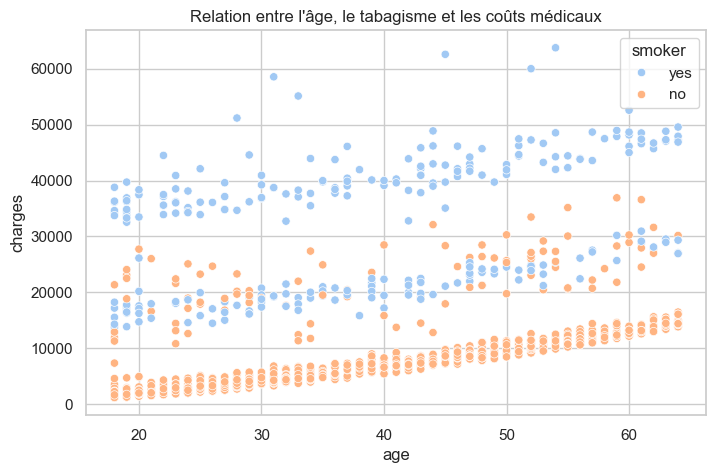

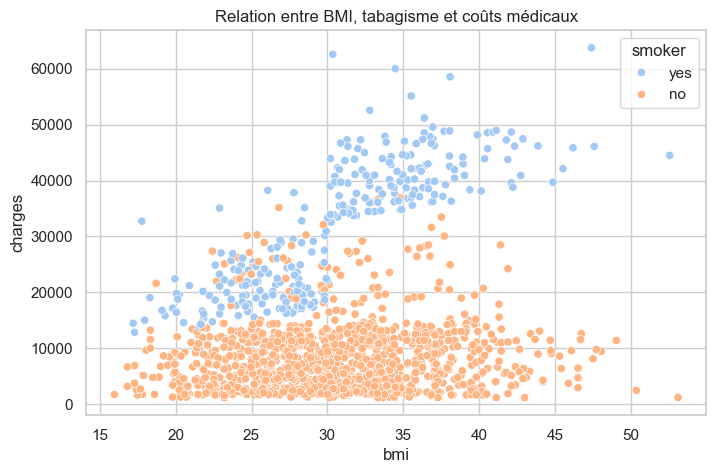

In [ ]:
# Effet de l'âge et du BMI sur les charges
plt.figure(figsize=(8, 5))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df)
plt.title("Relation entre l'âge, le tabagisme et les coûts médicaux")
plt.show()
plt.figure(figsize=(8, 5))
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df)
plt.title("Relation entre BMI, tabagisme et coûts médicaux")
plt.show()

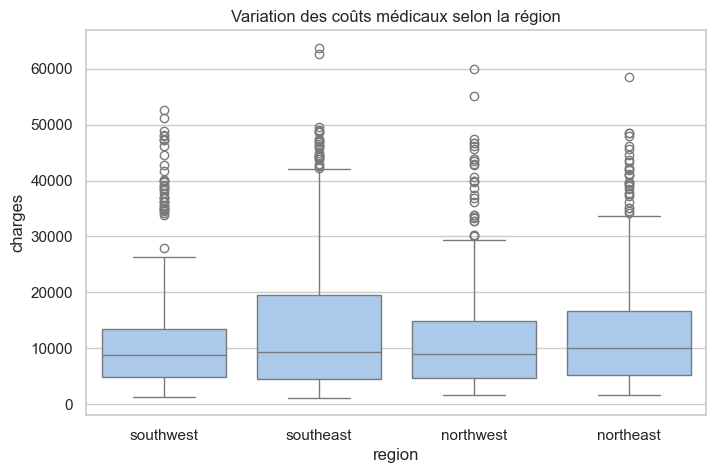

In [ ]:
# Différence selon la région
plt.figure(figsize=(8, 5))
sns.boxplot(x='region', y='charges', data=df)
plt.title("Variation des coûts médicaux selon la région")
plt.show()

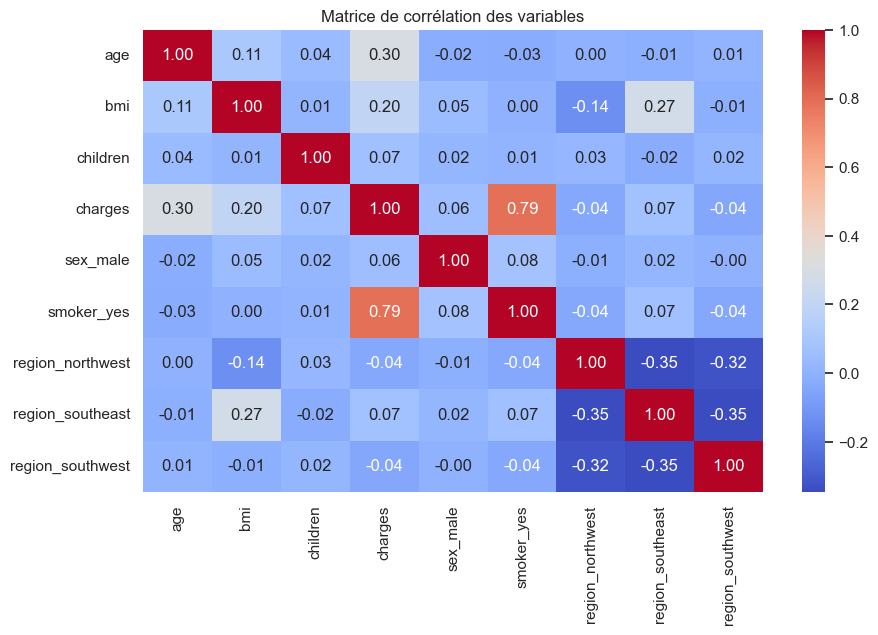

In [ ]:
# Matrice de corrélation (heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(df_encoded.corr(), cmap='coolwarm', annot=True, fmt=".2f")
plt.title("Matrice de corrélation des variables")
plt.show()

In [ ]:
#___Machine learning par la régression linéaire simple___
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Variable explicative : fumeur (smoker_yes)
X_simple = df_encoded[['smoker_yes']]
y_simple = df_encoded['charges']

# Création du modèle
model_simple = LinearRegression()
model_simple.fit(X_simple, y_simple)

# Prédictions
y_pred_simple = model_simple.predict(X_simple)

# Coefficients
intercept = model_simple.intercept_
coef = model_simple.coef_[0]

print(f"🔹 Équation de la droite de régression simple : charges = {intercept:.2f} + {coef:.2f} * smoker_yes")

🔹 Équation de la droite de régression simple : charges = 8440.66 + 23609.57 * smoker_yes


In [ ]:
# Evaluation du modèle
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_simple, y_pred_simple)
rmse = np.sqrt(mean_squared_error(y_simple, y_pred_simple))
r2 = r2_score(y_simple, y_pred_simple)

print(f"\n📊 Évaluation du modèle :")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")


📊 Évaluation du modèle :
MAE  : 5661.91
RMSE : 7465.11
R²   : 0.620


In [ ]:
# Équation de la droite de régression
intercept = model_simple.intercept_
coef = model_simple.coef_[0]
print(f"📈 Équation : charges = {intercept:.2f} + {coef:.2f} * smoker_yes")
print(f"MAE={mae:.2f}   RMSE={rmse:.2f}   R²={r2:.3f}")

📈 Équation : charges = 8440.66 + 23609.57 * smoker_yes
MAE=5661.91   RMSE=7465.11   R²=0.620


In [ ]:
# Interprétation des coefficients
print("\n📊 Interprétation des coefficients :")

if coef > 0:
    print(f"➡️ Le coefficient positif ({coef:.2f}) indique que le fait d'être fumeur "
          f"augmente en moyenne le coût médical de {coef:.2f} unités monétaires.")
else:
    print(f"➡️ Le coefficient négatif ({coef:.2f}) indique que le fait d'être fumeur "
          f"réduit en moyenne le coût médical de {abs(coef):.2f} unités monétaires.")

print(f"➡️ L'ordonnée à l'origine (intercept = {intercept:.2f}) représente "
      f"le coût moyen pour un non-fumeur (smoker_yes = 0).")

print(f"\n🔹 Donc :")
print(f"   - Pour un non-fumeur, les charges estimées ≈ {intercept:.2f}")
print(f"   - Pour un fumeur, les charges estimées ≈ {intercept + coef:.2f}")


📊 Interprétation des coefficients :
➡️ Le coefficient positif (23609.57) indique que le fait d'être fumeur augmente en moyenne le coût médical de 23609.57 unités monétaires.
➡️ L'ordonnée à l'origine (intercept = 8440.66) représente le coût moyen pour un non-fumeur (smoker_yes = 0).

🔹 Donc :
   - Pour un non-fumeur, les charges estimées ≈ 8440.66
   - Pour un fumeur, les charges estimées ≈ 32050.23


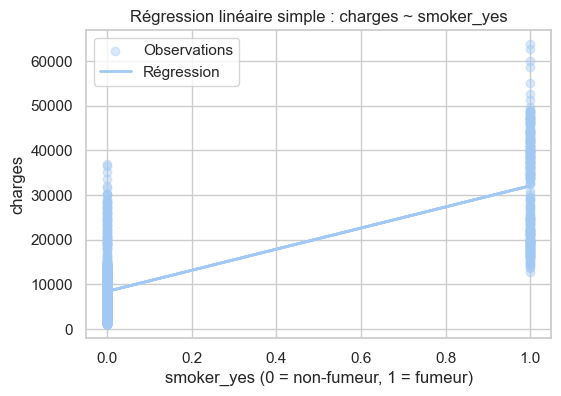

In [ ]:
# Visualisation des performances
plt.figure(figsize=(6,4))
plt.scatter(X_simple, y_simple, alpha=0.4, label='Observations')
plt.plot(X_simple, y_pred_simple, linewidth=2, label='Régression')
plt.xlabel('smoker_yes (0 = non-fumeur, 1 = fumeur)')
plt.ylabel('charges')
plt.title('Régression linéaire simple : charges ~ smoker_yes')
plt.legend()
plt.show()

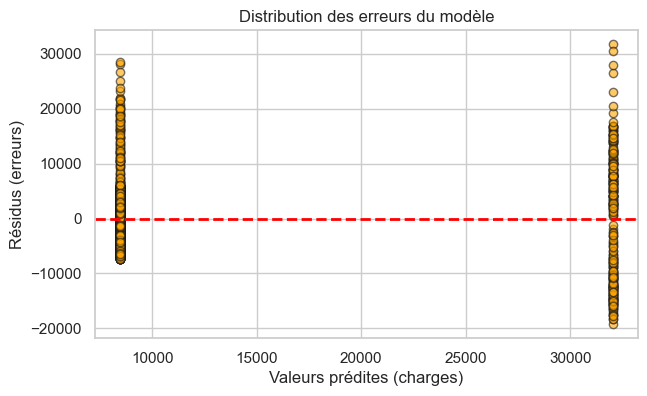

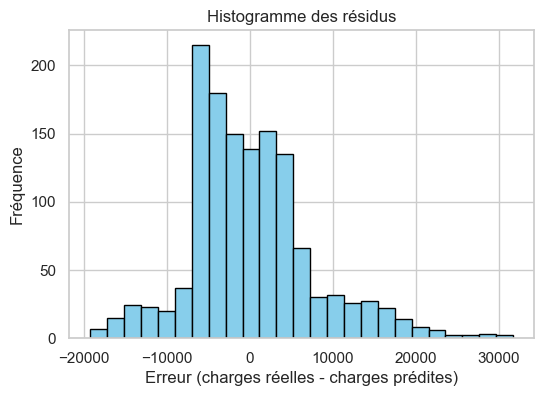

In [ ]:
# Visualisation des erreurs
residuals = y_simple - y_pred_simple

plt.figure(figsize=(7,4))
plt.scatter(y_pred_simple, residuals, alpha=0.6, color='orange', edgecolor='k')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel("Valeurs prédites (charges)")
plt.ylabel("Résidus (erreurs)")
plt.title("Distribution des erreurs du modèle")
plt.show()

# Histogramme des résidus
plt.figure(figsize=(6,4))
plt.hist(residuals, bins=25, color='skyblue', edgecolor='black')
plt.title("Histogramme des résidus")
plt.xlabel("Erreur (charges réelles - charges prédites)")
plt.ylabel("Fréquence")
plt.show()

In [ ]:
#___Machine learning par la régression logistique___
# Création de la variable cible binaire : 1 = frais médicaux élevés, 0 = faibles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
threshold = df_encoded['charges'].median()
df_encoded['high_cost'] = (df['charges'] > threshold).astype(int)

In [ ]:
# Préparation des données pour la classification
# Variables explicative et cible
X = df_encoded[['smoker_yes']]
y = df_encoded['high_cost']

# Division en jeu d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation (très importante pour KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Entraînement du modèle KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Prédictions
y_pred = knn.predict(X_test_scaled)
y_proba = knn.predict_proba(X_test_scaled)[:,1]

# Évaluation
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy={acc:.3f}")
print(f"Precision={prec:.3f}")
print(f"Recall={rec:.3f}")
print(f"F1-score={f1:.3f}")
print(f"AUC={auc:.3f}")

Accuracy=0.507
Precision=0.507
Recall=1.000
F1-score=0.673
AUC=0.721


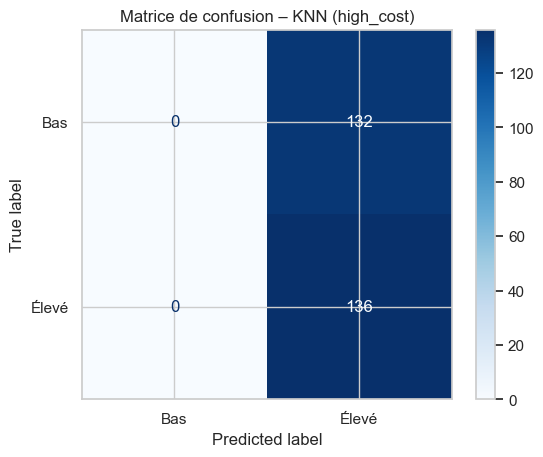

In [ ]:
# Matrice de confusion
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Bas", "Élevé"])
disp.plot(cmap="Blues")
plt.title("Matrice de confusion – KNN (high_cost)")
plt.show()

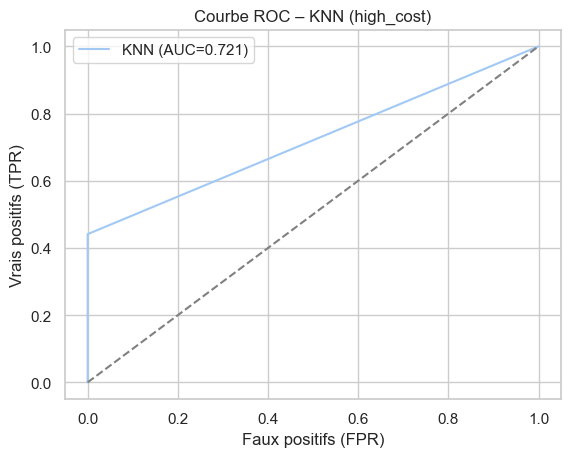

In [ ]:
# Tracé de la courbe ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=f'KNN (AUC={auc:.3f})')
plt.plot([0,1], [0,1], '--', color='gray')
plt.xlabel('Faux positifs (FPR)')
plt.ylabel('Vrais positifs (TPR)')
plt.title('Courbe ROC – KNN (high_cost)')
plt.legend()
plt.show()

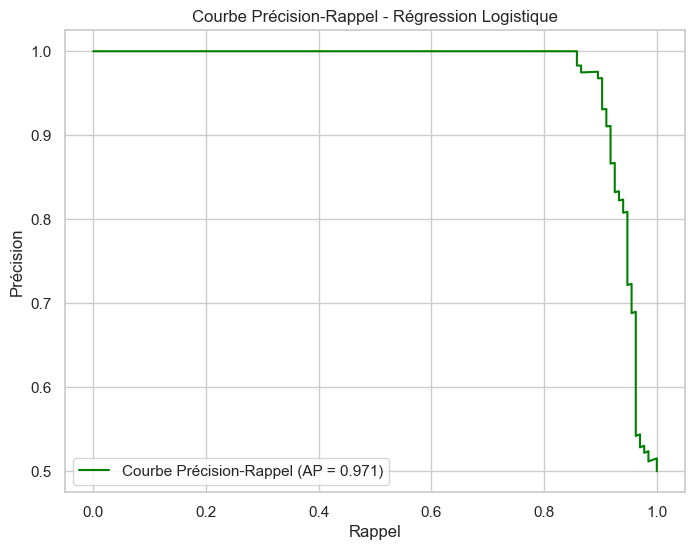

In [ ]:
# Courbe de précision/rappel
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='green', label=f'Courbe Précision-Rappel (AP = {ap:.3f})')
plt.xlabel('Rappel')
plt.ylabel('Précision')
plt.title('Courbe Précision-Rappel - Régression Logistique')
plt.legend(loc='lower left')
plt.show()

In [ ]:
#___Prédiction de nouvelles données___
# Fonction de préprocessing pour de nouvelles données
def preprocess_new(raw_df: pd.DataFrame) -> pd.DataFrame:
    """
    Reproduit le même preprocessing que pour le modèle.
    - One-hot encoding
    - Alignement des colonnes
    - Standardisation
    """
    dummies = pd.get_dummies(raw_df, drop_first=True)

    # Ajouter les colonnes manquantes ou retirer les colonnes en trop
    for col in X.columns:
        if col not in dummies.columns:
            dummies[col] = 0
    dummies = dummies[X.columns]

    # Standardisation des variables numériques (avec le scaler entraîné)
    num_cols = ['age', 'bmi', 'children']
    dummies[num_cols] = scaler.transform(dummies[num_cols])

    return dummies

# Fonction pour prédire un seul patient
def predict_patient(age, sex, bmi, children, smoker, region):
    """
    Retourne les prédictions du coût médical et la probabilité de coût élevé
    pour un seul individu.
    """
    new_df = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region
    }])

    # Prétraitement
    X_new = preprocess_new(new_df)

    # Régression linéaire (charges)
    pred_charge = model.predict(X_new)[0]

    # Régression logistique (probabilité high_cost)
    prob_high = log_model.predict_proba(X_new)[0, 1]
    pred_high = int(prob_high >= 0.5)

    print(f"🧍 Patient : {sex}, {age} ans, IMC {bmi}, {children} enfant(s), "
          f"fumeur : {smoker}, région : {region}")
    print(f"💰 Coût médical estimé : {pred_charge:.2f} $")
    print(f"📊 Probabilité d’avoir des frais élevés : {prob_high*100:.1f}%")
    print(f"🏷️ Classe prédite : {'Haut coût' if pred_high == 1 else 'Faible coût'}")

    return {
        "age": age, "sex": sex, "bmi": bmi, "children": children, "smoker": smoker, "region": region,
        "pred_charges": round(pred_charge, 2),
        "proba_high_cost": round(prob_high, 3),
        "pred_high_cost": pred_high
    }


# Exemple : prédiction individuelle
predict_patient(45, "male", 31.5, 2, "yes", "southeast")


🧍 Patient : male, 45 ans, IMC 31.5, 2 enfant(s), fumeur : yes, région : southeast
💰 Coût médical estimé : 0.56 $
📊 Probabilité d’avoir des frais élevés : 64.2%
🏷️ Classe prédite : Haut coût


{'age': 45,
 'sex': 'male',
 'bmi': 31.5,
 'children': 2,
 'smoker': 'yes',
 'region': 'southeast',
 'pred_charges': 0.56,
 'proba_high_cost': 0.642,
 'pred_high_cost': 1}

In [ ]:
# Prédictions pour plusieurs nouveaux patients + export CSV
# Création d’un mini dataset de nouveaux cas
new_patients = pd.DataFrame([
    {"age": 25, "sex": "female", "bmi": 22.0, "children": 0, "smoker": "no",  "region": "southwest"},
    {"age": 50, "sex": "male",   "bmi": 33.4, "children": 3, "smoker": "yes", "region": "southeast"},
    {"age": 38, "sex": "female", "bmi": 27.5, "children": 1, "smoker": "no",  "region": "northeast"},
    {"age": 60, "sex": "male",   "bmi": 29.2, "children": 2, "smoker": "yes", "region": "northwest"},
])

# Prétraitement identique
X_new = preprocess_new(new_patients)

# Prédictions linéaires
new_patients["pred_charges"] = model.predict(X_new)

# Prédictions logistiques
new_patients["proba_high_cost"] = log_model.predict_proba(X_new)[:, 1]
new_patients["pred_high_cost"] = (new_patients["proba_high_cost"] >= 0.5).astype(int)

# Arrondir pour lisibilité
new_patients["pred_charges"] = new_patients["pred_charges"].round(2)
new_patients["proba_high_cost"] = new_patients["proba_high_cost"].round(3)

# Afficher les résultats
print("✅ Prédictions pour nouveaux patients :")
display(new_patients)
new_patients.to_csv("predictions_new_patients.csv", index=False)
print("\n📁 Fichier exporté : predictions_new_patients.csv")

✅ Prédictions pour nouveaux patients :


,age,sex,bmi,children,smoker,region,pred_charges,proba_high_cost,pred_high_cost
0,25,female,22.0,0,no,southwest,0.06,0.028,0
1,50,male,33.4,3,yes,southeast,1.18,0.998,1
2,38,female,27.5,1,no,northeast,0.41,0.336,0
3,60,male,29.2,2,yes,northwest,1.41,1.000,1



📁 Fichier exporté : predictions_new_patients.csv
